<a href="https://colab.research.google.com/github/samarthverma4/100_days_100_web_project/blob/main/CNN_QuickDraw_Augmentation_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Table of Contents
1. [Setup](#setup)
2. [Task 1 — Dataset Loading and Preprocessing](#task-1)
3. [Task 2 — CNN Model Development](#task-2)
4. [Task 3 — Baseline Model Training (no augmentation)](#task-3)
5. [Task 4 — Data Augmentation](#task-4)

## 0. Setup

In [18]:
import os, urllib.parse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "None (CPU will be slower)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [19]:
# ---------------- Configuration ----------------
CLASSES = ["apple", "banana", "cat", "airplane", "bicycle"]   # any QuickDraw category names
SAMPLES_PER_CLASS = 6000      # drawn randomly from each class's full .npy file
IMG_SIZE = 32                 # common dimension (raw QuickDraw bitmaps are 28x28)
BATCH_SIZE = 128
EPOCHS = 5
NUM_CLASSES = len(CLASSES)
BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"

## Task 1 — Dataset Loading and Preprocessing

In [20]:
X_list, y_list = [], []
for idx, name in enumerate(CLASSES):
    url = BASE_URL + urllib.parse.quote(name) + ".npy"
    path = tf.keras.utils.get_file(f"{name}.npy", url, cache_subdir="quickdraw")
    data = np.load(path, mmap_mode="r")                       # (N, 784) uint8, memory-mapped
    sel = np.sort(rng.choice(len(data), SAMPLES_PER_CLASS, replace=False))
    X_list.append(np.asarray(data[sel]).reshape(-1, 28, 28))
    y_list.append(np.full(SAMPLES_PER_CLASS, idx, dtype=np.int32))
    print(f"{name:10s}: {len(data):>7,} drawings available -> {SAMPLES_PER_CLASS:,} sampled")

X_raw = np.concatenate(X_list)
y_all = np.concatenate(y_list)
print("\nRaw data:", X_raw.shape, X_raw.dtype, "| labels:", y_all.shape)

apple     : 144,722 drawings available -> 6,000 sampled
banana    : 307,936 drawings available -> 6,000 sampled
cat       : 123,202 drawings available -> 6,000 sampled
airplane  : 151,623 drawings available -> 6,000 sampled
bicycle   : 126,527 drawings available -> 6,000 sampled

Raw data: (30000, 28, 28) uint8 | labels: (30000,)


In [21]:
# Stratified split: 70% train / 15% validation / 15% test (fixed seed -> reused for both models)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(X_train_raw):,} | Val: {len(X_val_raw):,} | Test: {len(X_test_raw):,}")
print("Per-class train counts:", np.bincount(y_train))

Train: 21,000 | Val: 4,500 | Test: 4,500
Per-class train counts: [4200 4200 4200 4200 4200]


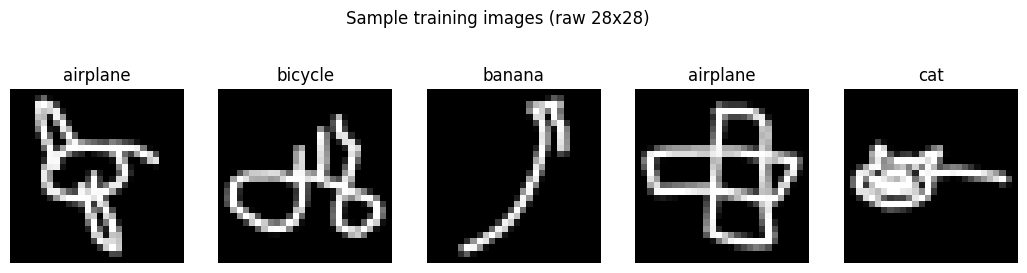

In [22]:
# Five sample images with class labels
idx = rng.choice(len(X_train_raw), 5, replace=False)
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, i in zip(axes, idx):
    ax.imshow(X_train_raw[i], cmap="gray")
    ax.set_title(CLASSES[y_train[i]]); ax.axis("off")
plt.suptitle("Sample training images (raw 28x28)", y=1.05)
plt.show()

In [23]:
def preprocess(X):
    """uint8 (N,28,28) -> float32 (N,IMG_SIZE,IMG_SIZE,1) in [0,1]."""
    X = X.astype("float32")[..., np.newaxis] / 255.0                 # normalize
    X = tf.image.resize(X, (IMG_SIZE, IMG_SIZE), method="bilinear")  # resize to common dimension
    return tf.clip_by_value(X, 0.0, 1.0).numpy()

X_train = preprocess(X_train_raw)
X_val   = preprocess(X_val_raw)
X_test  = preprocess(X_test_raw)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print(f"Pixel range: [{X_train.min():.2f}, {X_train.max():.2f}]")

X_train: (21000, 32, 32, 1) | y_train: (21000,)
X_val:   (4500, 32, 32, 1) | y_val:   (4500,)
X_test:  (4500, 32, 32, 1) | y_test:  (4500,)
Pixel range: [0.00, 1.00]


In [24]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y, shuffle=False, augment=None):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if augment is not None:                       # only ever passed for the training set
        ds = ds.map(lambda x, t: (augment(x, training=True), t), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds      = make_ds(X_train, y_train, shuffle=True)
train_eval_ds = make_ds(X_train, y_train)          # clean, unshuffled — for evaluation only
val_ds        = make_ds(X_val, y_val)
test_ds       = make_ds(X_test, y_test)

## Task 2 — CNN Model Development

In [25]:
def build_cnn(name="cnn"):
    tf.keras.utils.set_random_seed(SEED)           # identical initial weights every call
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax"),   # multiclass output
    ], name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",  # integer labels
                  metrics=["accuracy"])
    return model

base_model = build_cnn("baseline_cnn")
base_model.summary()
trainable = int(sum(np.prod(w.shape) for w in base_model.trainable_weights))
print(f"\nTotal trainable parameters: {trainable:,}")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,589 (1.36 MB)

 Trainable params: 355,589 (1.36 MB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters: 355,589


## Task 3 — Baseline Model Training (no augmentation)

In [26]:
hist_base = base_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)

pd.DataFrame(hist_base.history, index=range(1, EPOCHS + 1)).rename_axis("epoch").round(4)

Epoch 1/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.8608 - loss: 0.4108 - val_accuracy: 0.9376 - val_loss: 0.2038
Epoch 2/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9405 - loss: 0.1860 - val_accuracy: 0.9551 - val_loss: 0.1595
Epoch 3/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9570 - loss: 0.1372 - val_accuracy: 0.9476 - val_loss: 0.1547
Epoch 4/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9651 - loss: 0.1115 - val_accuracy: 0.9631 - val_loss: 0.1254
Epoch 5/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9694 - loss: 0.0960 - val_accuracy: 0.9658 - val_loss: 0.1124


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.8608,0.4108,0.9376,0.2038
2,0.9405,0.1860,0.9551,0.1595
3,0.9570,0.1372,0.9476,0.1547
4,0.9651,0.1115,0.9631,0.1254
5,0.9694,0.0960,0.9658,0.1124


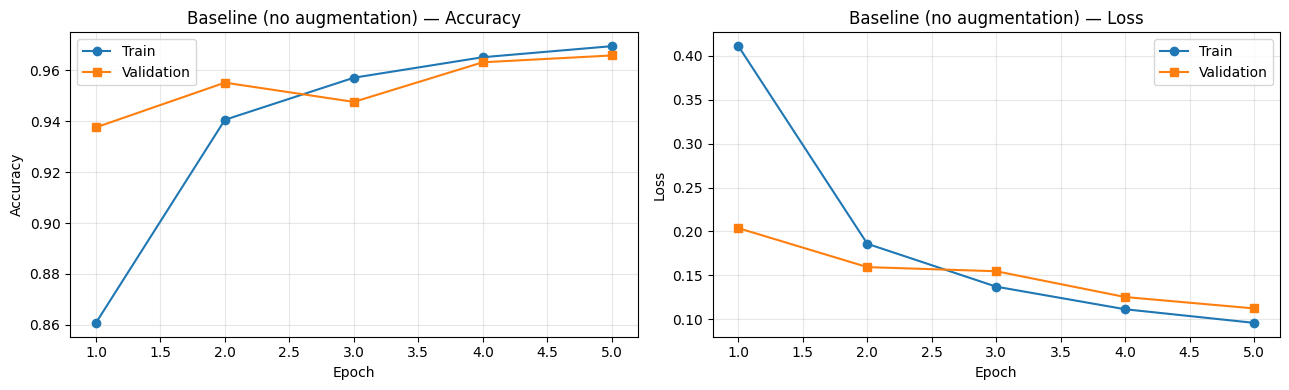

In [27]:
def plot_history(h, title):
    ep = range(1, len(h.history["accuracy"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, h.history["accuracy"], "o-", label="Train")
    ax[0].plot(ep, h.history["val_accuracy"], "s-", label="Validation")
    ax[0].set(title=f"{title} — Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, h.history["loss"], "o-", label="Train")
    ax[1].plot(ep, h.history["val_loss"], "s-", label="Validation")
    ax[1].set(title=f"{title} — Loss", xlabel="Epoch", ylabel="Loss"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_history(hist_base, "Baseline (no augmentation)")

## Task 4 — Data Augmentation
Four techniques: rotation, zoom, shift (translation), horizontal flip.
`fill_mode="constant"` with `fill_value=0` keeps the black background (the default `reflect` would mirror strokes into the empty border).
Horizontal flip is safe here because a mirrored apple/cat/airplane is still the same class (contrast with digits — see Q9).

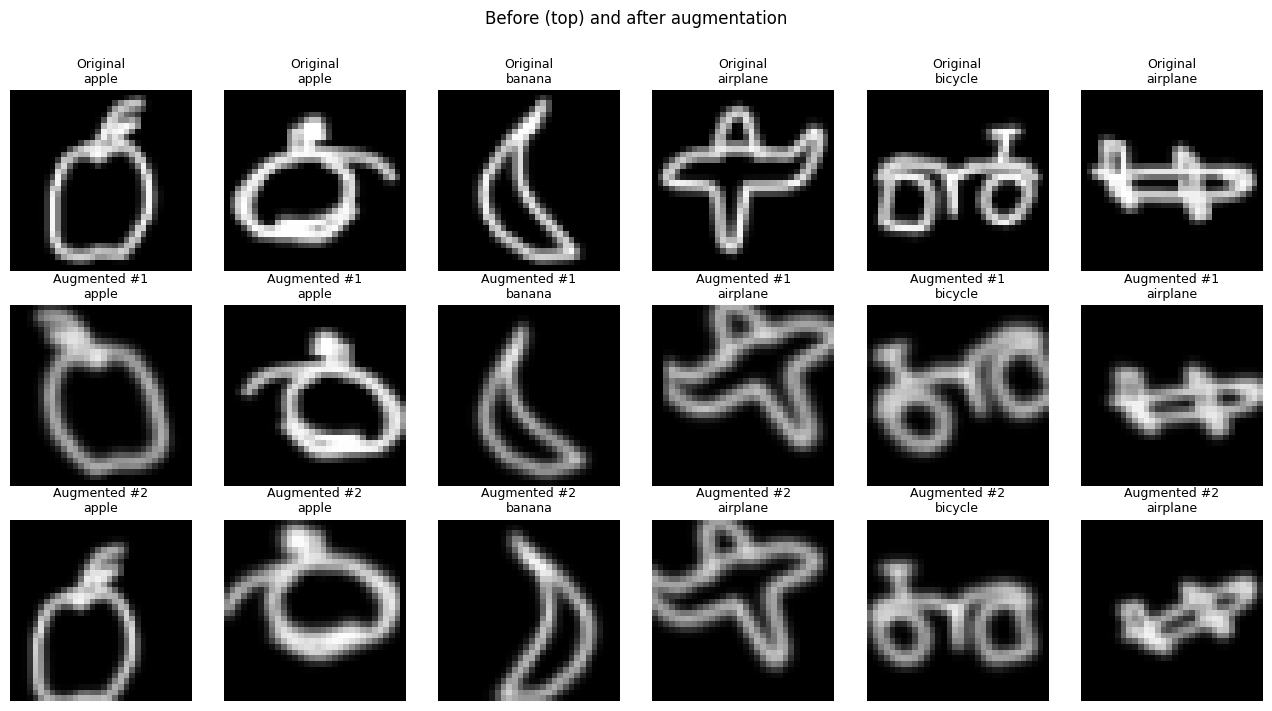

In [28]:
augmenter = keras.Sequential([
    layers.RandomRotation(0.08, fill_mode="constant", fill_value=0.0, seed=SEED),        # ±~29°
    layers.RandomZoom(0.15, fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomTranslation(0.10, 0.10, fill_mode="constant", fill_value=0.0, seed=SEED),
    layers.RandomFlip("horizontal", seed=SEED),
], name="augmenter")

# Before vs after augmentation
idx = rng.choice(len(X_train), 6, replace=False)
sample = tf.constant(X_train[idx])
rows = [("Original", X_train[idx])] + [(f"Augmented #{k}", np.array(augmenter(sample, training=True))) for k in (1, 2)]

fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for r, (label, imgs) in enumerate(rows):
    for c in range(6):
        axes[r, c].imshow(imgs[c].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"{label}\n{CLASSES[y_train[idx[c]]]}", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Before (top) and after augmentation", y=1.01)
plt.tight_layout(); plt.show()

In [29]:
train_aug_ds = make_ds(X_train, y_train, shuffle=True, augment=augmenter)   # training data ONLY

aug_model = build_cnn("augmented_cnn")      # same architecture, same initial weights
hist_aug = aug_model.fit(train_aug_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)

pd.DataFrame(hist_aug.history, index=range(1, EPOCHS + 1)).rename_axis("epoch").round(4)

Epoch 1/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.7632 - loss: 0.6652 - val_accuracy: 0.9096 - val_loss: 0.2819
Epoch 2/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8885 - loss: 0.3435 - val_accuracy: 0.9318 - val_loss: 0.2237
Epoch 3/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9130 - loss: 0.2709 - val_accuracy: 0.9447 - val_loss: 0.1756
Epoch 4/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9316 - loss: 0.2161 - val_accuracy: 0.9507 - val_loss: 0.1656
Epoch 5/5
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9386 - loss: 0.1886 - val_accuracy: 0.9576 - val_loss: 0.1375


,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.7632,0.6652,0.9096,0.2819
2,0.8885,0.3435,0.9318,0.2237
3,0.9130,0.2709,0.9447,0.1756
4,0.9316,0.2161,0.9507,0.1656
5,0.9386,0.1886,0.9576,0.1375


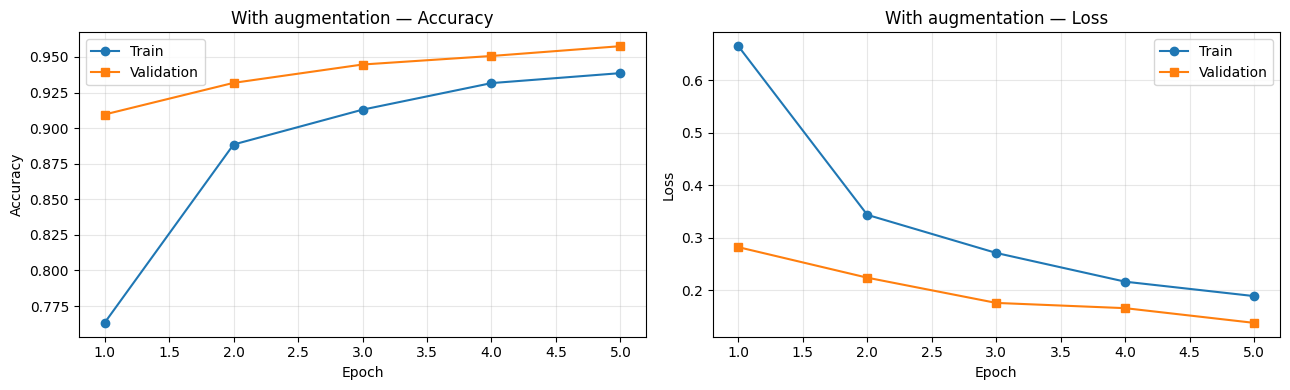

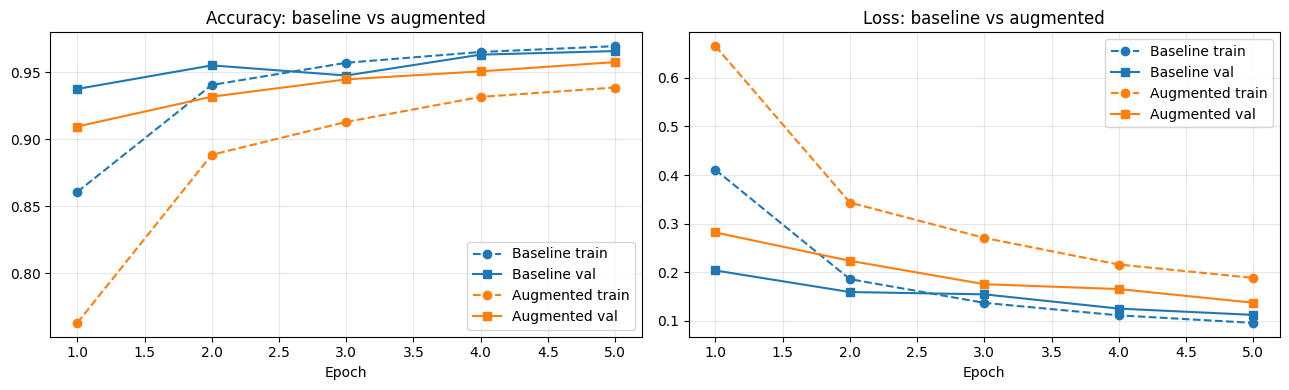

In [30]:
plot_history(hist_aug, "With augmentation")

# Side-by-side comparison of both runs
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for h, lbl, c in [(hist_base, "Baseline", "tab:blue"), (hist_aug, "Augmented", "tab:orange")]:
    ax[0].plot(ep, h.history["accuracy"], "o--", color=c, label=f"{lbl} train")
    ax[0].plot(ep, h.history["val_accuracy"], "s-", color=c, label=f"{lbl} val")
    ax[1].plot(ep, h.history["loss"], "o--", color=c, label=f"{lbl} train")
    ax[1].plot(ep, h.history["val_loss"], "s-", color=c, label=f"{lbl} val")
ax[0].set(title="Accuracy: baseline vs augmented", xlabel="Epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set(title="Loss: baseline vs augmented", xlabel="Epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

,Train acc (logged),Train acc (clean),Val acc,Test acc,Train−Val gap,Test loss
Model,,,,,,
Baseline (no aug),0.9694,0.9826,0.9658,0.9613,0.0037,0.1247
With augmentation,0.9386,0.9600,0.9576,0.9553,-0.0189,0.1499


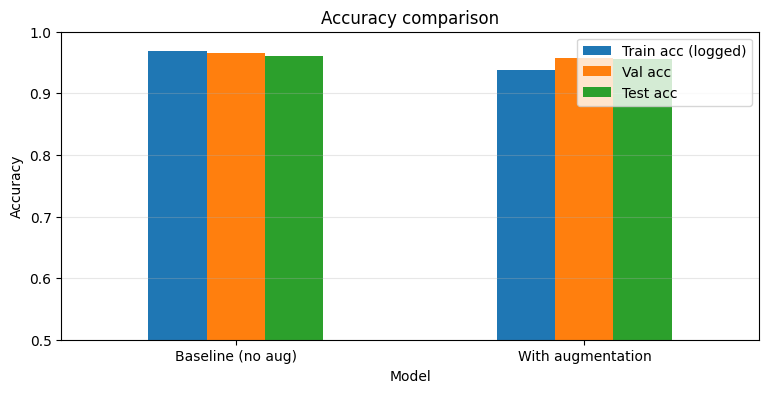

In [31]:
rows = []
for name, model, h in [("Baseline (no aug)", base_model, hist_base), ("With augmentation", aug_model, hist_aug)]:
    _, clean_train_acc = model.evaluate(train_eval_ds, verbose=0)
    val_loss, val_acc  = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    rows.append({"Model": name,
                 "Train acc (logged)": h.history["accuracy"][-1],
                 "Train acc (clean)": clean_train_acc,
                 "Val acc": val_acc,
                 "Test acc": test_acc,
                 "Train−Val gap": h.history["accuracy"][-1] - val_acc,
                 "Test loss": test_loss})
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.style.format("{:.4f}").highlight_max(subset=["Val acc", "Test acc"], color="#c6efce"))

comparison[["Train acc (logged)", "Val acc", "Test acc"]].plot.bar(figsize=(9, 4), rot=0, ylim=(0.5, 1.0))
plt.title("Accuracy comparison"); plt.ylabel("Accuracy"); plt.grid(axis="y", alpha=.3); plt.show()

In [32]:
# Auto-generated observations from the ACTUAL numbers above
b, a = comparison.loc["Baseline (no aug)"], comparison.loc["With augmentation"]
print(f"Test accuracy : baseline {b['Test acc']:.4f} vs augmented {a['Test acc']:.4f} "
      f"({(a['Test acc'] - b['Test acc']) * 100:+.2f} pp)")
print(f"Val accuracy  : baseline {b['Val acc']:.4f} vs augmented {a['Val acc']:.4f} "
      f"({(a['Val acc'] - b['Val acc']) * 100:+.2f} pp)")
print(f"Train−Val gap : baseline {b['Train−Val gap']:+.4f} vs augmented {a['Train−Val gap']:+.4f}")
if a["Test acc"] >= b["Test acc"]:
    print("-> Augmentation improved (or matched) generalization in this run.")
else:
    print("-> Augmentation did NOT improve test accuracy in this run — with only 5 epochs the "
          "augmented model sees a harder task and may simply need more epochs to converge.")

Test accuracy : baseline 0.9613 vs augmented 0.9553 (-0.60 pp)
Val accuracy  : baseline 0.9658 vs augmented 0.9576 (-0.82 pp)
Train−Val gap : baseline +0.0037 vs augmented -0.0189
-> Augmentation did NOT improve test accuracy in this run — with only 5 epochs the augmented model sees a harder task and may simply need more epochs to converge.


Using for predictions: Baseline (no aug)


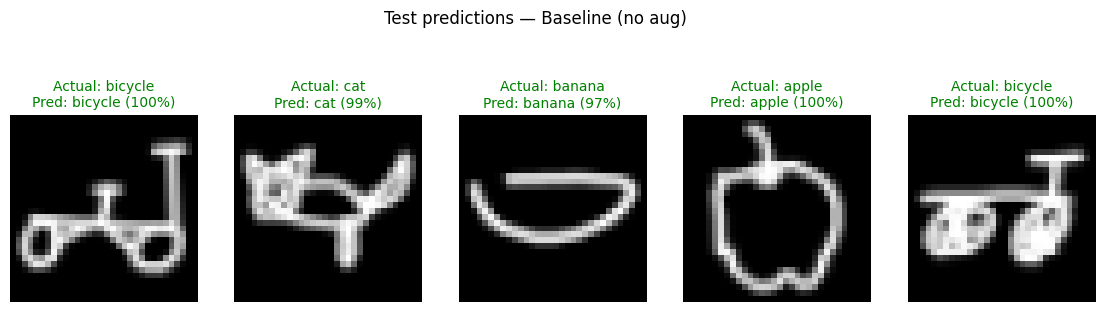

In [33]:
best_name = comparison["Test acc"].idxmax()
best_model = base_model if best_name.startswith("Baseline") else aug_model
print("Using for predictions:", best_name)

probs = best_model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)

# Five random test images: actual vs predicted
idx = rng.choice(len(X_test), 5, replace=False)
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4))
for ax, i in zip(axes, idx):
    ok = y_pred[i] == y_test[i]
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"Actual: {CLASSES[y_test[i]]}\nPred: {CLASSES[y_pred[i]]} ({probs[i].max():.0%})",
                 color="green" if ok else "red", fontsize=10)
    ax.axis("off")
plt.suptitle(f"Test predictions — {best_name}", y=1.08); plt.show()

Misclassified: 174 / 4,500 (3.87%)


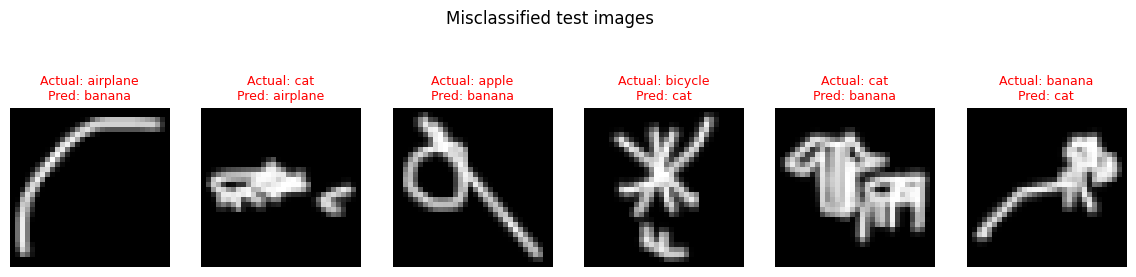


Example #5: actual = airplane, predicted = banana
   banana     0.808
   cat        0.101
   apple      0.053


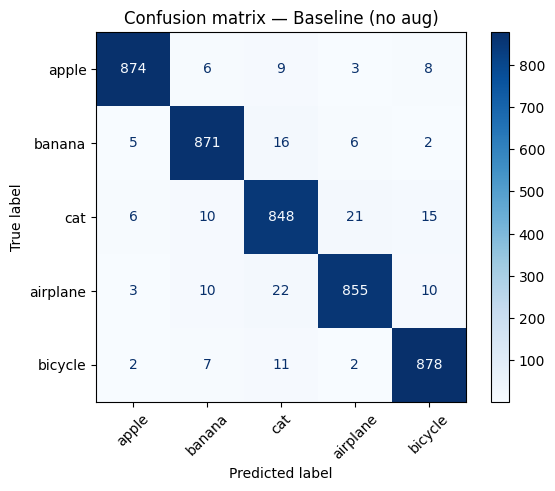

              precision    recall  f1-score   support

       apple     0.9820    0.9711    0.9765       900
      banana     0.9635    0.9678    0.9656       900
         cat     0.9360    0.9422    0.9391       900
    airplane     0.9639    0.9500    0.9569       900
     bicycle     0.9617    0.9756    0.9686       900

    accuracy                         0.9613      4500
   macro avg     0.9614    0.9613    0.9613      4500
weighted avg     0.9614    0.9613    0.9613      4500



In [34]:
# Misclassified examples
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong):,} / {len(y_test):,} ({len(wrong) / len(y_test):.2%})")

if len(wrong):
    show = wrong[:6]
    fig, axes = plt.subplots(1, len(show), figsize=(2.4 * len(show), 3.2))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, show):
        ax.imshow(X_test[i].squeeze(), cmap="gray")
        ax.set_title(f"Actual: {CLASSES[y_test[i]]}\nPred: {CLASSES[y_pred[i]]}", color="red", fontsize=9)
        ax.axis("off")
    plt.suptitle("Misclassified test images", y=1.05); plt.show()

    i = wrong[0]
    top3 = probs[i].argsort()[::-1][:3]
    print(f"\nExample #{i}: actual = {CLASSES[y_test[i]]}, predicted = {CLASSES[y_pred[i]]}")
    for k in top3:
        print(f"   {CLASSES[k]:10s} {probs[i][k]:.3f}")

# Confusion matrix — shows which class pairs get confused
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion matrix — {best_name}"); plt.show()
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))